# Exploring the data

This notebook accompanies two chapters of the guide
([the datasets](https://qwertylab.dev/guides/feature-emergence/05-the-datasets/), [the SNR](https://qwertylab.dev/guides/feature-emergence/06-where-the-key-leaks/)). The chapters give the
orientation; here we actually
open the files and look at the numbers.

We answer five questions:

1. What is inside a dataset file, and how do we look at it?
2. What do raw traces look like?
3. How different are the datasets from each other (scale and noise)?
4. At which time samples does the key leak? (the SNR)
5. Where does the leakage hide on a masked device? (the shares)

Figures produced (shown in the chapters):
`outputs/figures/02_single_trace.png`, `02_traces_overview.png`,
`02_stats_table.png`, `02_snr_buckets.png`, `02_snr_annotated.png`,
`02_snr_curves.png`, `02_snr_shares.png`.

In [1]:
# Note: no `matplotlib.use("Agg")` here — plain `python` runs fall back to a
# headless backend automatically, and the Jupyter kernel uses the inline
# backend, so the same code saves PNGs *and* displays figures in notebooks.
import matplotlib.pyplot as plt
import numpy as np

from feature_emergence.config import DATA_DIR, OUTPUTS_DIR
from feature_emergence.utils import load_dataset

out = OUTPUTS_DIR / "figures"
out.mkdir(parents=True, exist_ok=True)


def snr(x, y):
    """SNR of every time sample, each label group weighted by its number of traces.

    The paper's `snr_fast` weights every group equally. With full-byte labels
    (256 equally likely groups) the two agree; with Hamming-weight labels, where
    groups 0 and 8 hold 1/256 of the traces each, `snr_fast` comes out several
    times larger.
    """
    x = np.asarray(x, dtype=np.float64)
    mean_all = x.mean(axis=0)
    signal = np.zeros(x.shape[1])
    noise = np.zeros(x.shape[1])
    for g in np.unique(y):
        xg = x[y == g]
        signal += len(xg) * (xg.mean(axis=0) - mean_all) ** 2
        noise += len(xg) * xg.var(axis=0)
    return signal / noise

## 1. What is inside a dataset file?

Each dataset is a single **`.h5` file** — an *HDF5* file. HDF5 (Hierarchical
Data Format) is a container for large numerical arrays: inside, the data is
organized like a filesystem, with *groups* (folders) and *datasets*
(arrays). You cannot open it in a text editor; you explore it with a
library, here `h5py`.

Let's open the CHES_CTF file and print its full structure:

In [2]:
import h5py

CHES_FILE = DATA_DIR / "ches_ctf" / "ches_ctf_nopoi_window_20.h5"

with h5py.File(CHES_FILE, "r") as f:
    def show(name, obj):
        if isinstance(obj, h5py.Dataset):
            print(f"{name:40s} shape={str(obj.shape):15s} dtype={obj.dtype}")
    f.visititems(show)

Attack_traces/metadata                   shape=(10000,)        dtype=[('plaintext', 'u1', (16,)), ('ciphertext', 'u1', (16,)), ('key', 'u1', (16,))]
Attack_traces/traces                     shape=(10000, 15000)  dtype=float16
Profiling_traces/metadata                shape=(30000,)        dtype=[('plaintext', '<f8', (16,)), ('ciphertext', '<f8', (16,)), ('key', '<f8', (16,))]
Profiling_traces/traces                  shape=(30000, 15000)  dtype=float16


Two groups — `Profiling_traces` and `Attack_traces` — each with two arrays:

- `traces`: one measurement trace per row (thousands of time samples per
  row).
- `metadata`: one record per trace with the cryptographic values that
  produced it (plaintext, key, and ciphertext here).

Let's read the metadata of a single attack trace — record number 0:

In [3]:
with h5py.File(CHES_FILE, "r") as f:
    record = f["Attack_traces/metadata"][0]

print("plaintext :", bytes(record["plaintext"]).hex())
print("key       :", bytes(record["key"]).hex())
print("ciphertext:", bytes(record["ciphertext"]).hex())

plaintext : c549dd73446310a073b9f9c6bdc7e66d
key       : 175cf2997a8583413c77dfac7e6c59d8
ciphertext: e70e50e7a0829e5f6691ac64dde13056


This is one real AES-128 encryption: the device encrypted exactly this
plaintext with exactly this key and produced exactly this ciphertext (you
can verify it with any AES calculator). While it did so, an instrument
recorded the power trace stored in the same row of `traces`. That pairing —
*the crypto values* plus *the physical measurement* — is the whole dataset.

## 2. Loading the datasets with the package loaders

Opening files by hand works, but the package loaders hide the format
differences between datasets (dtypes, label computation, leakage models) and
give us trace arrays plus leakage labels directly.

To keep this notebook fast we read a subset of the profiling set of each
dataset — 20k–30k traces are enough for stable statistics.

In [4]:
DATASETS = [
    ("ASCADr",   load_dataset("ascad-variable", traces_dim=2000,  leakage_model="ID", n_prof=20000)),
    ("ESHARD",   load_dataset("eshard",         traces_dim=1400,  leakage_model="HW", n_prof=20000)),
    ("CHES_CTF", load_dataset("ches_ctf",       traces_dim=15000, leakage_model="HW", n_prof=30000)),
]

for name, ds in DATASETS:
    print(f"{name:9s} profiling traces: {ds.x_profiling.shape}  labels: {ds.profiling_labels.shape}")

ASCADr    profiling traces: (20000, 2000)  labels: (20000,)
ESHARD    profiling traces: (20000, 1400)  labels: (20000,)
CHES_CTF  profiling traces: (30000, 15000)  labels: (30000,)


## 3. One single trace

Before statistics, look at one trace on its own: the power consumption of
the CHES_CTF device during the first round of one AES encryption (the file
stores a window around that round, not the whole encryption).

saved: /home/operator/Projects/teravon/proyecto-dirigido/feature_emergence/outputs/figures/02_single_trace.png


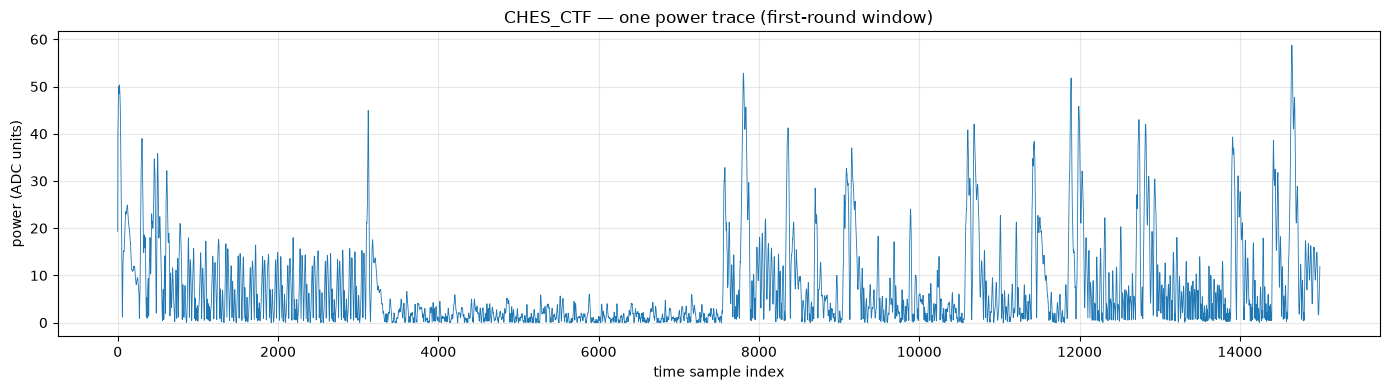

In [5]:
ds = dict(DATASETS)["CHES_CTF"]

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(ds.x_profiling[0], lw=0.6)
ax.set_title("CHES_CTF — one power trace (first-round window)")
ax.set_xlabel("time sample index")
ax.set_ylabel("power (ADC units)")
ax.grid(alpha=0.3)
fig.tight_layout()

fig.savefig(out / "02_single_trace.png", dpi=150)
print("saved:", out / "02_single_trace.png")
plt.show()

Each of the 15,000 points is one instantaneous power measurement. Nothing in
this shape tells a human where the key is — the leakage is statistical and
only shows up across *many* traces. That is what the next sections are for.

## 4. What does a trace look like across datasets?

Overlaying a handful of traces per dataset shows how different the
measurement campaigns are: trace lengths differ by an order of magnitude
(1,400 to 15,000 samples), and so do the shapes — compare the short traces
of ESHARD with the long, spiky traces of CHES_CTF.

The campaigns differ mainly in the physical measurement: ESHARD and ASCADr
record the chip's electromagnetic emanations with a probe near its surface,
while CHES_CTF records the power drawn from the supply. Within one dataset
the setup is fixed, so traces differ only slightly from one recording to
the next; most of that variation is measurement noise, and the small
data-dependent part is what the attack exploits.

saved: /home/operator/Projects/teravon/proyecto-dirigido/feature_emergence/outputs/figures/02_traces_overview.png


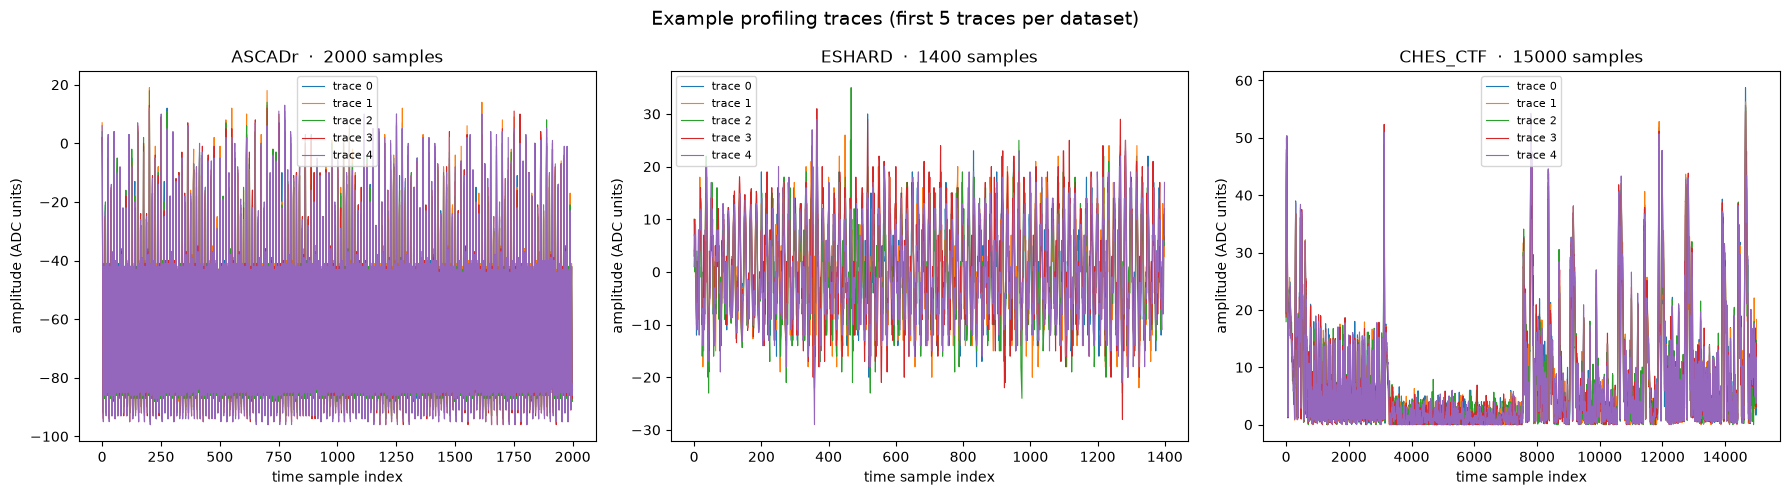

In [6]:
N_TRACES = 5  # traces to overlay per dataset

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, ds) in zip(axes, DATASETS):
    for i in range(N_TRACES):
        ax.plot(ds.x_profiling[i], lw=0.8, label=f"trace {i}")
    ax.set_title(f"{name}  ·  {ds.x_profiling.shape[1]} samples")
    ax.set_xlabel("time sample index")
    ax.set_ylabel("amplitude (ADC units)")
    ax.legend(fontsize=8)

fig.suptitle("Example profiling traces (first 5 traces per dataset)", fontsize=14)
fig.tight_layout()

fig.savefig(out / "02_traces_overview.png", dpi=150)
print("saved:", out / "02_traces_overview.png")
plt.show()

## 5. Scale and noise: dataset statistics

Before any statistics on leakage, a numerical profile: shape, dtype, and the
basic statistics of the traces. Two details worth noticing:

- ASCADr traces are stored as `int8` (raw ADC codes) while CHES_CTF uses
  `float16` — scale and resolution differ by orders of magnitude.
- The per-trace standard deviation is a rough noise floor: it tells us how
  much of the signal is *not* systematic.

These differences are why models scale their inputs before training.

In [7]:
def trace_stats(x):
    # cast to float32: CHES_CTF traces are float16 and global sums overflow
    x = x.astype(np.float32)
    per_trace_std = x.std(axis=1)
    return (
        x.shape,
        str(x.dtype),
        round(float(x.mean()), 3),
        round(float(x.std()), 3),
        float(x.min()),
        float(x.max()),
        round(float(per_trace_std.mean()), 3),
    )

rows = [("dataset", "shape", "dtype", "mean", "std", "min", "max", "mean(trace std)")]
for name, ds in DATASETS:
    rows.append((name,) + trace_stats(ds.x_profiling))

for row in rows:
    print(" | ".join(str(c) for c in row))

dataset | shape | dtype | mean | std | min | max | mean(trace std)
ASCADr | (20000, 2000) | float32 | -62.965 | 25.851 | -98.0 | 25.0 | 25.848
ESHARD | (20000, 1400) | float32 | -0.029 | 9.271 | -48.0 | 53.0 | 9.255
CHES_CTF | (30000, 15000) | float32 | 6.779 | 8.477 | 0.0 | 115.75 | 8.39


saved: /home/operator/Projects/teravon/proyecto-dirigido/feature_emergence/outputs/figures/02_stats_table.png


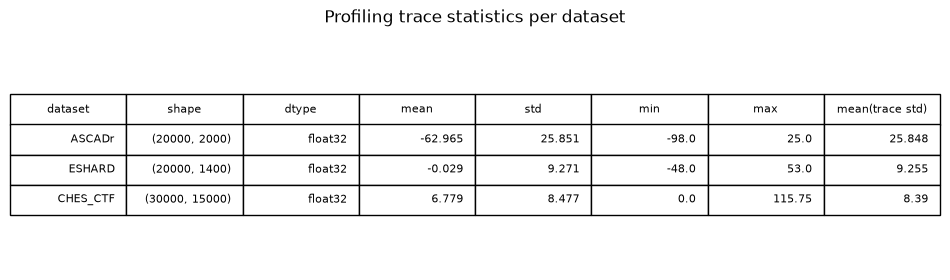

In [8]:
fig, ax = plt.subplots(figsize=(12, 3))
ax.axis("off")
tbl = ax.table(cellText=rows[1:], colLabels=rows[0], loc="center")
tbl.set_fontsize(11)
tbl.scale(1, 1.8)
ax.set_title("Profiling trace statistics per dataset", pad=12)

fig.savefig(out / "02_stats_table.png", dpi=150, bbox_inches="tight")
print("saved:", out / "02_stats_table.png")
plt.show()

## 6. Where does the key leak? — the SNR

A trace has thousands of time samples, but only a few of them carry
information about the key. To find them, the standard tool in side-channel
analysis is the **Signal-to-Noise Ratio (SNR)**, computed independently for
each time sample:

```
SNR(t) = variance of the group means / average variance inside the groups
```

Both averages run over traces, so a group counts as often as it has traces
(the definition in the guide's chapter 6).

What are the groups? Fix one time sample `t` and take the column of values
it takes across all profiling traces. We know the plaintext and key of each
trace, so we can compute the target intermediate of each trace — here the
Hamming weight of the first S-box output, a label in 0..8 — and split the
column into one bucket per label value.

### The SNR up close: two single time samples

Before any curves, look at the raw ingredients. We use ESHARD here, where
the effect is clearest. We take two single time samples — one at the
highest SNR peak, one far from any peak — and plot the measured value at
that instant for a few thousand traces, grouped by leakage label. Each dot
is one trace; the red line joins the bucket averages.

- **Signal** = how far apart the bucket averages are from each other.
- **Noise** = how wide each dot cloud is vertically.

saved: /home/operator/Projects/teravon/proyecto-dirigido/feature_emergence/outputs/figures/02_snr_buckets.png


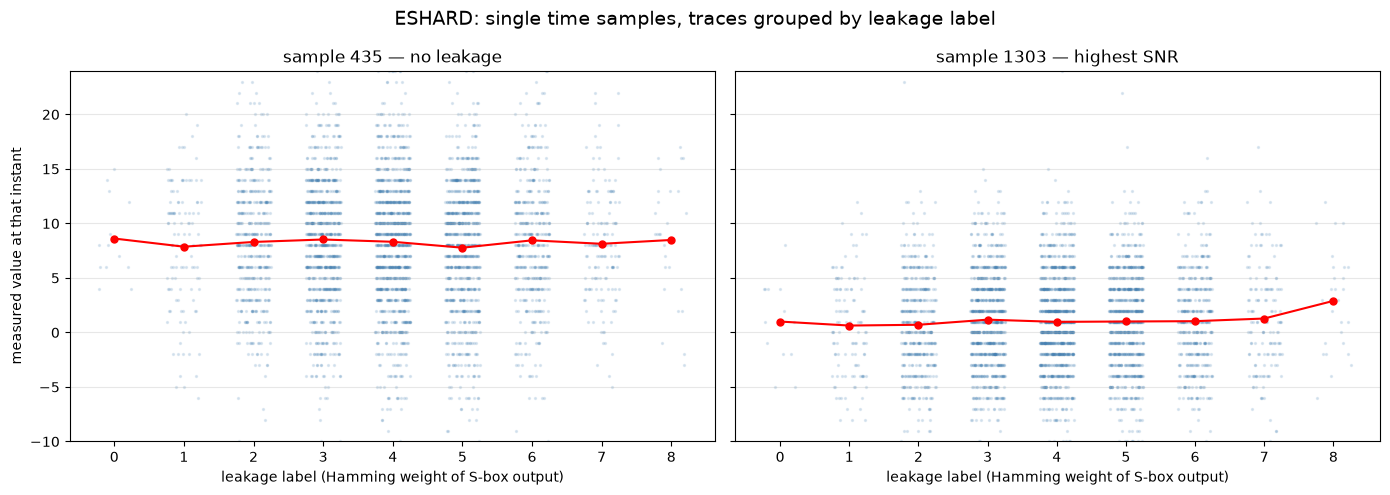

In [9]:
rng = np.random.default_rng(0)

name, ds = DATASETS[1]  # ESHARD, Hamming weight labels 0..8
x = ds.x_profiling.astype(np.float32)
y = ds.profiling_labels.astype(int)
snr_esh = snr(x, y)

t_peak = int(np.argmax(snr_esh))
t_quiet = int(np.argmin(snr_esh[: len(snr_esh) // 3]))  # far from the peak

subset = rng.choice(len(x), size=4000, replace=False)
ylo, yhi = np.percentile(x[subset][:, [t_quiet, t_peak]], [0.5, 99.5])

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, t, title in zip(
    axes,
    [t_quiet, t_peak],
    [f"sample {t_quiet} — no leakage", f"sample {t_peak} — highest SNR"],
):
    means = []
    for hw in range(9):
        idx = subset[y[subset] == hw]
        vals = x[idx, t]
        means.append(vals.mean())
        jitter = hw + rng.uniform(-0.25, 0.25, size=len(idx))
        ax.scatter(jitter, vals, s=2, alpha=0.15, color="steelblue")
    ax.plot(range(9), means, color="red", lw=1.5, marker=".", ms=10, zorder=5)
    ax.set_xticks(range(9))
    ax.set_xlabel("leakage label (Hamming weight of S-box output)")
    ax.set_title(title)
    ax.set_ylim(ylo, yhi)
    ax.grid(alpha=0.3, axis="y")

axes[0].set_ylabel("measured value at that instant")
fig.suptitle("ESHARD: single time samples, traces grouped by leakage label", fontsize=14)
fig.tight_layout()

fig.savefig(out / "02_snr_buckets.png", dpi=150)
print("saved:", out / "02_snr_buckets.png")
plt.show()

On the left, the nine bucket averages coincide: at that instant the
measurement is unrelated to the target byte, so knowing the label says
nothing — SNR ≈ 0. On the right, the averages rise with the Hamming weight
while each cloud keeps its own spread: that separation is the signal.

### Reading the SNR curve

Repeating the computation for all 1,400 samples gives the SNR curve. Below,
one raw trace and the SNR share the same time axis: the shaded band marks
the instants where the S-box output is physically computed and moved;
everywhere else the curve sits on the noise floor.

leakage band: samples 1303..1303 (1 samples)


saved: /home/operator/Projects/teravon/proyecto-dirigido/feature_emergence/outputs/figures/02_snr_annotated.png


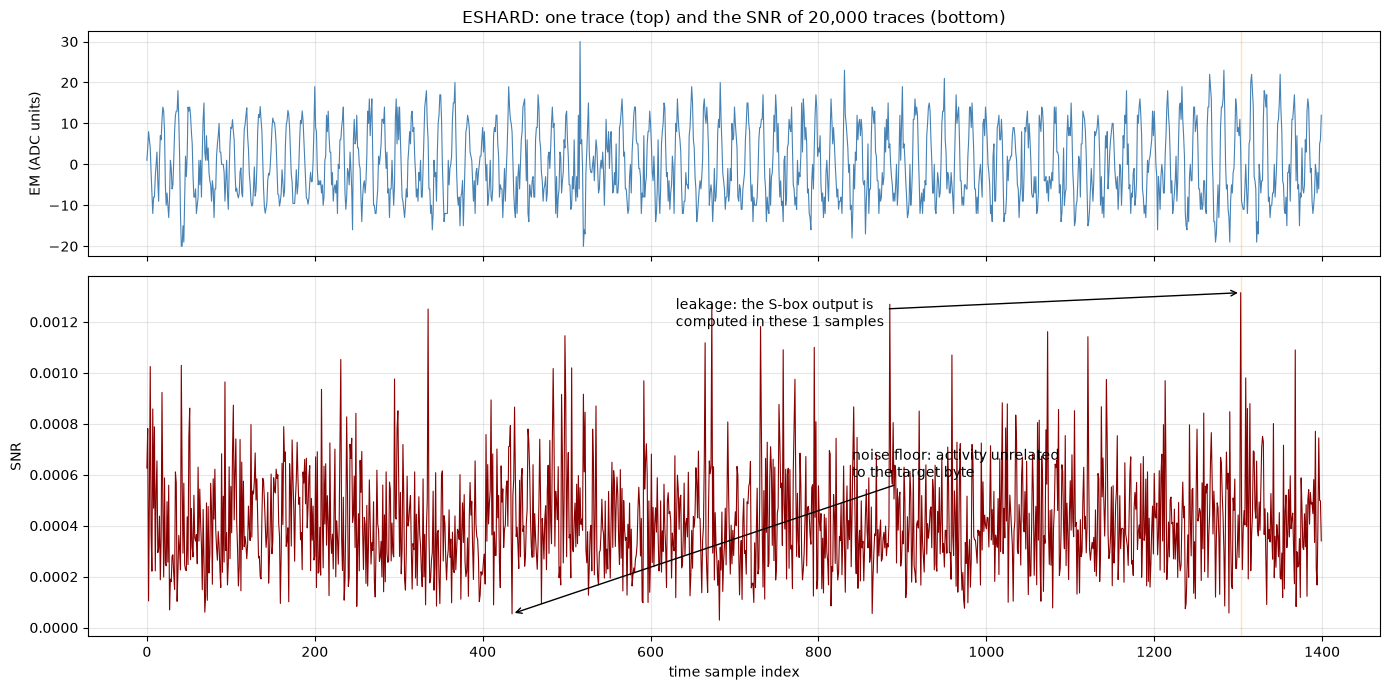

In [10]:
fig, axes = plt.subplots(
    2, 1, figsize=(14, 7), sharex=True, gridspec_kw={"height_ratios": [1, 1.6]}
)

axes[0].plot(x[0], lw=0.8, color="steelblue")
axes[0].set_ylabel("EM (ADC units)")
axes[0].set_title("ESHARD: one trace (top) and the SNR of 20,000 traces (bottom)")
axes[0].grid(alpha=0.3)

axes[1].plot(snr_esh, lw=0.8, color="darkred")
axes[1].set_ylabel("SNR")
axes[1].set_xlabel("time sample index")
axes[1].grid(alpha=0.3)

# leakage band: contiguous region around the highest peak above 5x the median
floor = np.median(snr_esh)
thr = 5 * floor
lo = t_peak
while lo > 0 and snr_esh[lo] > thr:
    lo -= 1
hi = t_peak
while hi < len(snr_esh) - 1 and snr_esh[hi] > thr:
    hi += 1
print(f"leakage band: samples {lo}..{hi} ({hi - lo + 1} samples)")
for ax in axes:
    ax.axvspan(lo, hi, color="orange", alpha=0.3)

axes[1].annotate(
    f"leakage: the S-box output is\ncomputed in these {hi - lo + 1} samples",
    xy=(t_peak, snr_esh[t_peak]),
    xytext=(0.45 * len(snr_esh), 0.9 * snr_esh[t_peak]),
    arrowprops={"arrowstyle": "->", "color": "black"},
    fontsize=10,
)
axes[1].annotate(
    "noise floor: activity unrelated\nto the target byte",
    xy=(t_quiet, snr_esh[t_quiet]),
    xytext=(0.6 * len(snr_esh), 0.45 * snr_esh[t_peak]),
    arrowprops={"arrowstyle": "->", "color": "black"},
    fontsize=10,
)

fig.tight_layout()
fig.savefig(out / "02_snr_annotated.png", dpi=150)
print("saved:", out / "02_snr_annotated.png")
plt.show()

How to read the curves for all three datasets:

- **Tall, narrow peaks**: leakage concentrated at a few clock cycles —
  typical of software AES, where operations run one byte at a time.
- **Low, flat profiles**: leakage spread thin or suppressed — masking pushes
  the peaks down, because the device computes on `S-box output XOR mask`
  with a fresh random mask per trace, so bucketing by the unmasked label
  mixes all masked values together and the bucket averages collapse.

The SNR is the baseline against which the feature-emergence analysis later
compares what a trained network actually learns on its own.

saved: /home/operator/Projects/teravon/proyecto-dirigido/feature_emergence/outputs/figures/02_snr_curves.png


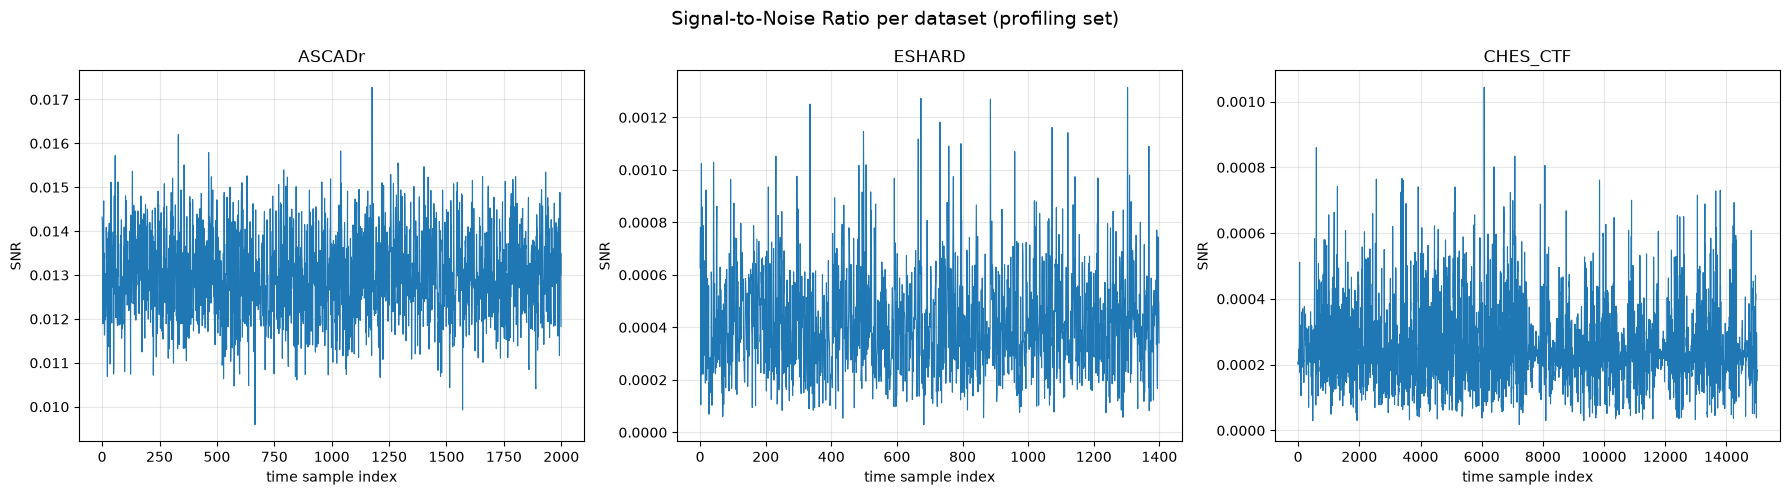

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, ds) in zip(axes, DATASETS):
    curve = snr(ds.x_profiling, ds.profiling_labels)
    ax.plot(curve, lw=0.8)
    ax.set_title(f"{name}")
    ax.set_xlabel("time sample index")
    ax.set_ylabel("SNR")
    ax.grid(alpha=0.3)

fig.suptitle("Signal-to-Noise Ratio per dataset (profiling set)", fontsize=14)
fig.tight_layout()

fig.savefig(out / "02_snr_curves.png", dpi=150)
print("saved:", out / "02_snr_curves.png")
plt.show()

## 7. Masking does not remove the leakage — it moves it into the shares

ASCADr's metadata include the mask used in every trace, so we can replay the
SNR computation three times on the *same* traces: against the unmasked
label `HW(Sbox[p ⊕ k])`, against the masked share `HW(Sbox[p ⊕ k] ⊕ m)`,
and against the mask `HW(m)` itself.

saved: /home/operator/Projects/teravon/proyecto-dirigido/feature_emergence/outputs/figures/02_snr_shares.png
  unmasked  max SNR = 0.0011 at sample 1976
  share     max SNR = 3.8245 at sample 1526
  mask      max SNR = 1.9858 at sample 970


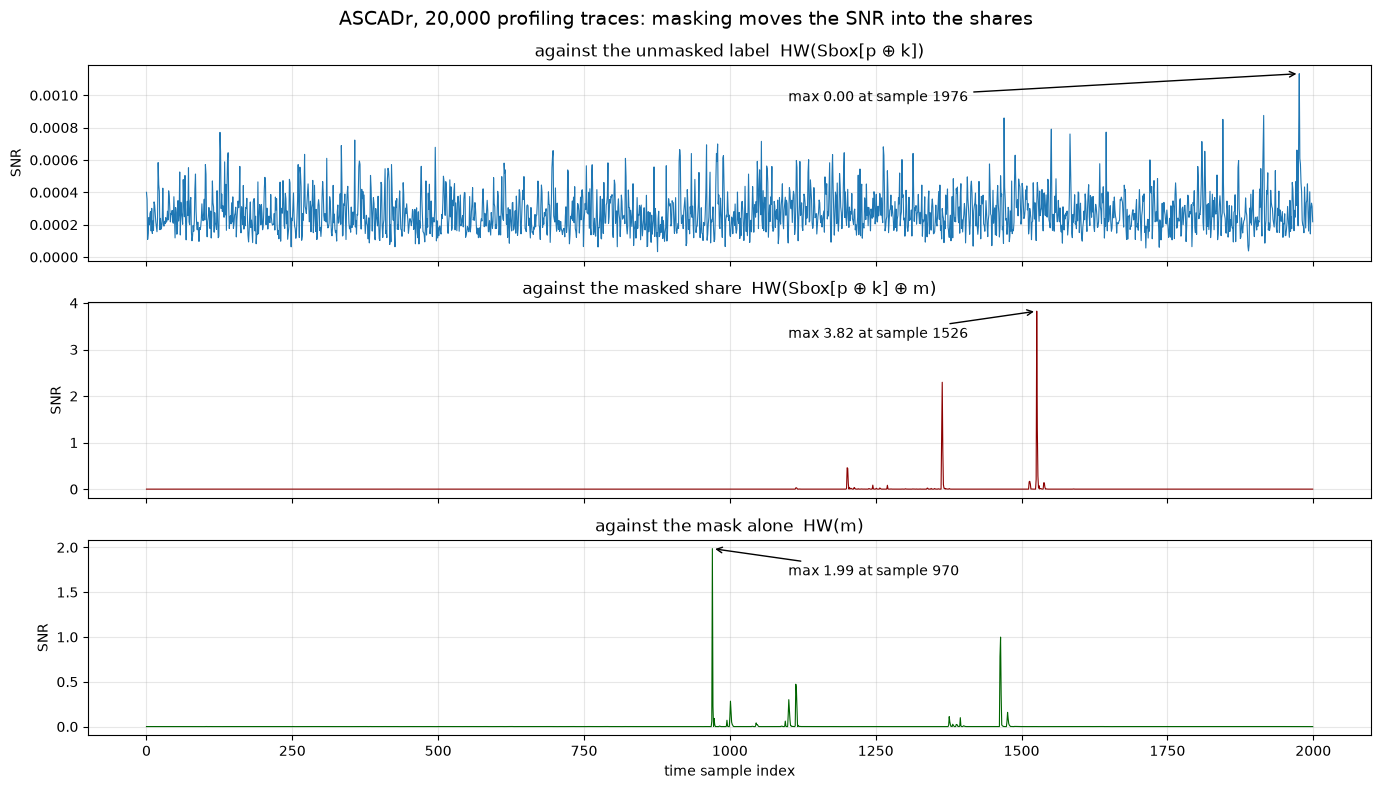

In [12]:
ds = dict(DATASETS)["ASCADr"]
tb = 2  # target byte used throughout the manual

x = ds.x_profiling.astype(np.float64)
labels_unmasked = ds.profiling_labels.astype(int)  # Sbox[p ⊕ k]
mask = ds.share1_profiling[tb].astype(int)         # m
share2 = ds.share2_profiling[tb].astype(int)       # Sbox[p ⊕ k] ⊕ m
assert np.array_equal(share2 ^ mask, labels_unmasked)  # share construction check


def hw(values):
    return np.array([bin(int(b)).count("1") for b in values])


panels = [
    (snr(x, hw(labels_unmasked)), "against the unmasked label  HW(Sbox[p ⊕ k])", "tab:blue"),
    (snr(x, hw(share2)), "against the masked share  HW(Sbox[p ⊕ k] ⊕ m)", "darkred"),
    (snr(x, hw(mask)), "against the mask alone  HW(m)", "darkgreen"),
]

fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
for ax, (curve, title, color) in zip(axes, panels):
    ax.plot(curve, lw=0.8, color=color)
    t_peak = int(np.argmax(curve))
    ax.annotate(
        f"max {curve.max():.2f} at sample {t_peak}",
        xy=(t_peak, curve.max()),
        xytext=(0.55 * len(curve), 0.85 * curve.max()),
        arrowprops={"arrowstyle": "->", "color": "black"},
        fontsize=10,
    )
    ax.set_ylabel("SNR")
    ax.set_title(title)
    ax.grid(alpha=0.3)
axes[-1].set_xlabel("time sample index")
fig.suptitle("ASCADr, 20,000 profiling traces: masking moves the SNR into the shares", fontsize=14)
fig.tight_layout()

fig.savefig(out / "02_snr_shares.png", dpi=150)
print("saved:", out / "02_snr_shares.png")
for name, (curve, _, _) in zip(["unmasked", "share", "mask"], panels):
    print(f"  {name:9s} max SNR = {curve.max():.4f} at sample {curve.argmax()}")
plt.show()

## Takeaways

- An `.h5` dataset is just two paired arrays: measurement traces (power or
  electromagnetic, depending on the campaign), and the cryptographic values
  that produced them.
- The three datasets differ in trace length, scale, and noise — an
  observation that holds for one does not automatically transfer.
- The leakage of the target intermediate is concentrated in identifiable
  time samples.
- Masking flattens the SNR against the unmasked label, but the leakage moves
  into the shares: on ASCADr the masked share peaks at SNR ≈ 3.8 while the
  unmasked label stays at the noise floor (≈ 0.001).
- These SNR curves mark *where* an analyst would look for the key — the
  reference for checking whether a network looks in the same place.